# Take-Home Assignment 05 — Part B: Practical Experiments
**Transfer Learning for Image Classification with Limited Data** (Oxford-IIIT Pet, 10 classes, ResNet-18)

This notebook runs conditions B1–B5 under a shared protocol and logs all metrics to `.csv` / `.json` files used in the report (Part C).

**Running on Google Colab:** `Runtime → Change runtime type → T4 GPU`, then `Runtime → Run all`. Outputs are saved to `outputs/` (`logs/`, `figures/`, `models/`) and zipped in the last cell.

**Design notes**
1. B1–B3 are trained without augmentation to isolate the effect of the training paradigm (scratch vs. feature extraction vs. fine-tuning). B4 is B3 with augmentation; the "no augmentation" scenario of B4 is the B3 run itself.
2. Frozen layers are also kept in `eval()` mode. `requires_grad=False` alone does not stop BatchNorm from updating its running statistics in `train()` mode.
3. Model selection uses validation Macro F1, so the test set is used only for final reporting (no data leakage).
4. The seed is fixed (42) for Python, NumPy, and PyTorch. All results come from a single seed.

## 1. Setup and Reproducibility

In [21]:
import os, json, time, random, zipfile, platform
import importlib.metadata as md
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms, datasets
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, confusion_matrix, classification_report
from tqdm.auto import tqdm

CFG = {
    "seed": 42,
    "batch_size": 32,
    "weight_decay": 1e-2,          # AdamW
    "max_epochs": 100,
    "patience": 5,                 # early stopping on validation loss
    "num_workers": 2,
    "resize_size": 256,
    "img_size": 224,
    "split": (0.70, 0.15, 0.15),   # train / validation / test
    "pretrained": True,            # ImageNet weights for B2-B5
    "b4_base": "B3",               # base condition for the augmentation test (B2 or B3)
    "b5_arch": "efficientnet_b0",  # or "mobilenet_v3_small"
    "data_root": "./data",
    "out_dir": "./outputs",
}

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

OUT = Path(CFG["out_dir"])
LOGS, FIGS, MODELS = OUT / "logs", OUT / "figures", OUT / "models"
for d in (LOGS, FIGS, MODELS):
    d.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


seed_everything(CFG["seed"])

# Plot style: training = blue, validation = orange
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titlesize": 11, "axes.labelsize": 10,
})
C_TRAIN, C_VAL, C_NEUTRAL = "#2a78d6", "#eb6834", "#7a7975"

print(f"PyTorch {torch.__version__} | torchvision {torchvision.__version__} | device = {DEVICE}")
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: no GPU detected. Enable Runtime > Change runtime type > T4 GPU.")

PyTorch 2.11.0+cu130 | torchvision 0.26.0+cu130 | device = cuda
GPU: Tesla T4


## 2. Dataset: Oxford-IIIT Pet (10-class subset)
Five cat breeds and five dog breeds are selected. The built-in `trainval` and `test` splits are merged (~2,000 images) and re-split with stratification into 70/15/15. Images are cached in RAM with the shorter side resized to 256 px (equivalent to `Resize(256)` in the pipeline), so training is not limited by JPEG decoding.

In [22]:
SELECTED_CLASSES = [
    "Abyssinian", "Bengal", "Egyptian Mau", "Maine Coon", "Siamese",   # cats
    "Beagle", "Boxer", "Pug", "Samoyed", "Shiba Inu",                  # dogs
]
NUM_CLASSES = len(SELECTED_CLASSES)


# Returns image paths and labels (0..9) of the selected classes, merging the trainval and test splits
def load_pet_subset(root, selected):
    ds_tv = datasets.OxfordIIITPet(root=root, split="trainval", target_types="category", download=True)
    ds_te = datasets.OxfordIIITPet(root=root, split="test", target_types="category", download=True)
    missing = [c for c in selected if c not in ds_tv.class_to_idx]
    assert not missing, f"Class names not found: {missing}. Valid examples: {ds_tv.classes[:5]}"
    keep = {ds_tv.class_to_idx[name]: new for new, name in enumerate(selected)}
    paths, labels = [], []
    for ds in (ds_tv, ds_te):
        for p, l in zip(ds._images, ds._labels):
            if l in keep:
                paths.append(Path(p))
                labels.append(keep[l])
    return paths, np.array(labels)


resize256 = transforms.Resize(CFG["resize_size"])

paths, LABELS = load_pet_subset(CFG["data_root"], SELECTED_CLASSES)
NAMES = [p.name for p in paths]
IMAGES = [resize256(Image.open(p).convert("RGB")) for p in tqdm(paths, desc="Caching images")]

print(f"Total images: {len(IMAGES)} | classes: {NUM_CLASSES}")
print(pd.Series(LABELS).map(dict(enumerate(SELECTED_CLASSES))).value_counts().sort_index().to_string())

Caching images:   0%|          | 0/1986 [00:00<?, ?it/s]

Total images: 1986 | classes: 10
Abyssinian      198
Beagle          200
Bengal          200
Boxer           199
Egyptian Mau    190
Maine Coon      200
Pug             200
Samoyed         200
Shiba Inu       200
Siamese         199


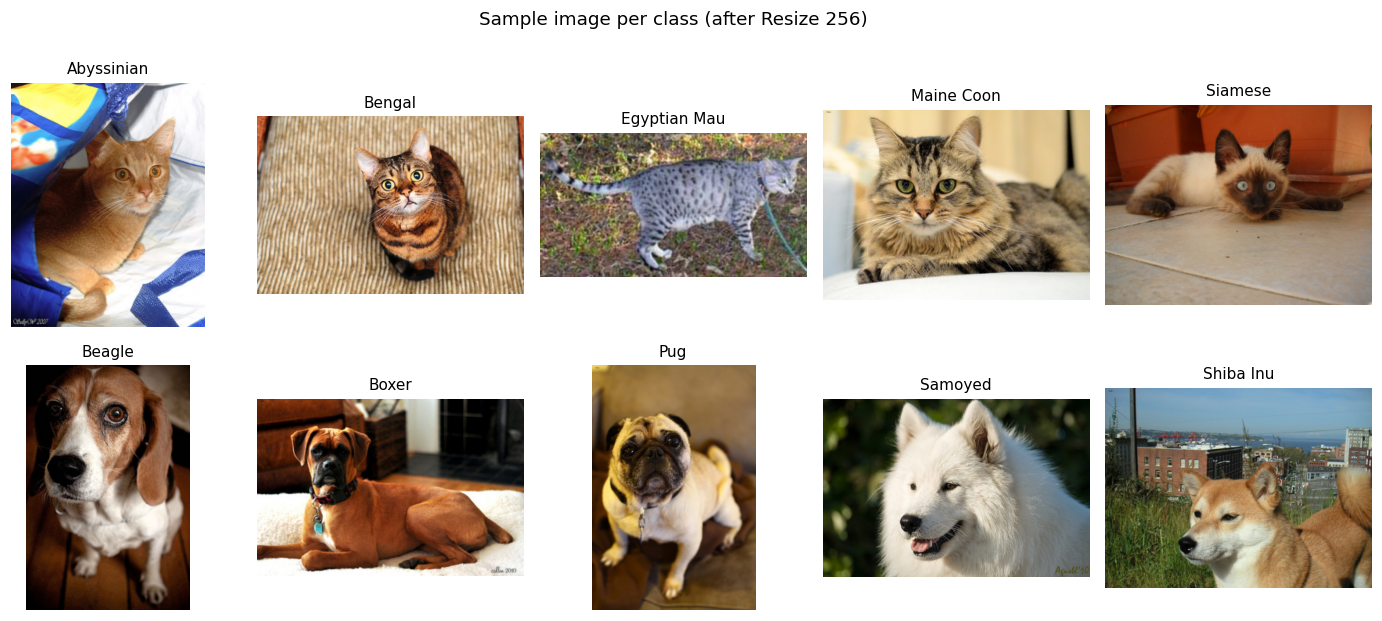

In [23]:
# One sample per class
fig, axes = plt.subplots(2, 5, figsize=(13, 5.6))
for c, ax in enumerate(axes.ravel()):
    j = int(np.where(LABELS == c)[0][0])
    ax.imshow(IMAGES[j]); ax.set_title(SELECTED_CLASSES[c], fontsize=10); ax.axis("off")
plt.suptitle("Sample image per class (after Resize 256)", y=1.0)
plt.tight_layout(); plt.show()

### 2.1 Stratified 70 / 15 / 15 split (performed before any transformation)

In [24]:
idx_all = np.arange(len(LABELS))
tr, va, te = CFG["split"]
idx_train, idx_tmp = train_test_split(idx_all, test_size=(va + te), stratify=LABELS, random_state=CFG["seed"])
idx_val, idx_test = train_test_split(idx_tmp, test_size=te / (va + te), stratify=LABELS[idx_tmp], random_state=CFG["seed"])

# No overlap between splits (prevents data leakage)
assert not (set(idx_train) & set(idx_val)) and not (set(idx_train) & set(idx_test)) and not (set(idx_val) & set(idx_test))
assert len(idx_train) + len(idx_val) + len(idx_test) == len(LABELS)

split_table = pd.DataFrame({
    "train": np.bincount(LABELS[idx_train], minlength=NUM_CLASSES),
    "val": np.bincount(LABELS[idx_val], minlength=NUM_CLASSES),
    "test": np.bincount(LABELS[idx_test], minlength=NUM_CLASSES),
}, index=SELECTED_CLASSES)
split_table.loc["TOTAL"] = split_table.sum()
print(split_table.to_string())

              train  val  test
Abyssinian      139   29    30
Bengal          140   30    30
Egyptian Mau    133   29    28
Maine Coon      140   30    30
Siamese         139   30    30
Beagle          140   30    30
Boxer           139   30    30
Pug             140   30    30
Samoyed         140   30    30
Shiba Inu       140   30    30
TOTAL          1390  298   298


## 3. Transforms and DataLoaders
Augmentation (RandomResizedCrop, horizontal flip, rotation, color jitter) is applied only to the training set in B4. Validation and test data always use a deterministic pipeline (`Resize 256 → CenterCrop 224 → Normalize`).

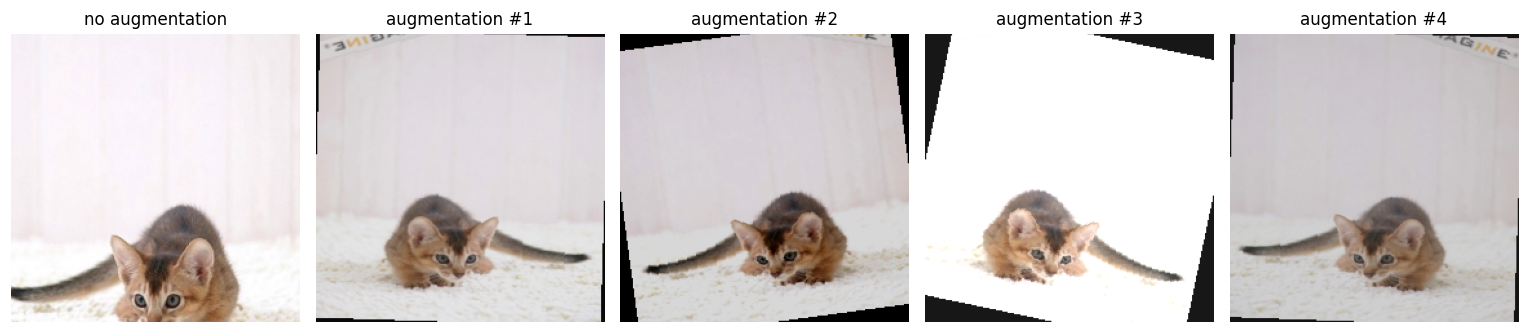

In [25]:
normalize = transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)

# Deterministic: validation, test, and training without augmentation
eval_tf = transforms.Compose([
    transforms.Resize(CFG["resize_size"]),
    transforms.CenterCrop(CFG["img_size"]),
    transforms.ToTensor(),
    normalize,
])

# Training with augmentation (B4)
train_tf_aug = transforms.Compose([
    transforms.Resize(CFG["resize_size"]),
    transforms.RandomResizedCrop(CFG["img_size"], scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    normalize,
])


# Fetches a cached image by global index and applies the transform
class PetDataset(Dataset):
    def __init__(self, indices, transform):
        self.indices, self.transform = np.asarray(indices), transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        g = int(self.indices[i])
        return self.transform(IMAGES[g]), int(LABELS[g])


def _worker_init(worker_id):
    s = torch.initial_seed() % 2**32
    np.random.seed(s); random.seed(s)


def make_loader(indices, transform, shuffle, seed=None):
    seed = CFG["seed"] if seed is None else seed
    g = torch.Generator(); g.manual_seed(seed)
    bs = CFG["batch_size"]
    return DataLoader(
        PetDataset(indices, transform), batch_size=bs, shuffle=shuffle,
        num_workers=CFG["num_workers"], pin_memory=(DEVICE.type == "cuda"),
        generator=g, worker_init_fn=_worker_init,
        drop_last=bool(shuffle and len(indices) % bs == 1),  # avoid a last batch of size 1 (BatchNorm)
    )


def denorm(t):
    m = torch.tensor(IMAGENET_MEAN)[:, None, None]; s = torch.tensor(IMAGENET_STD)[:, None, None]
    return (t * s + m).clamp(0, 1).permute(1, 2, 0).numpy()


# Original image vs. four random augmentations
j = int(idx_train[0])
fig, axes = plt.subplots(1, 5, figsize=(14, 3.2))
axes[0].imshow(denorm(eval_tf(IMAGES[j]))); axes[0].set_title("no augmentation")
for k in range(1, 5):
    axes[k].imshow(denorm(train_tf_aug(IMAGES[j]))); axes[k].set_title(f"augmentation #{k}")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

## 4. Model, Optimizer, Training Loop, and Logging
`build_model` supports three strategies:
- `scratch`: all parameters are trained from random initialization (B1)
- `feature_extraction`: the backbone is frozen and only the new head is trained (B2)
- `finetune_last`: the last block and the head are trained with differential learning rates (B3, B4)

Each run logs trainable parameters, learning rate per group, best epoch (lowest validation loss), training time, validation accuracy, and test Macro F1.

In [26]:
def build_model(arch, strategy, num_classes, pretrained):
    use_pre = pretrained and strategy != "scratch"
    if arch == "resnet18":
        w = models.ResNet18_Weights.IMAGENET1K_V1 if use_pre else None
        m = models.resnet18(weights=w)
    elif arch == "efficientnet_b0":
        w = models.EfficientNet_B0_Weights.IMAGENET1K_V1 if use_pre else None
        m = models.efficientnet_b0(weights=w)
    elif arch == "mobilenet_v3_small":
        w = models.MobileNet_V3_Small_Weights.IMAGENET1K_V1 if use_pre else None
        m = models.mobilenet_v3_small(weights=w)
    else:
        raise ValueError(f"Unknown architecture: {arch}")

    # Freeze all parameters unless training from scratch
    if strategy != "scratch":
        for p in m.parameters():
            p.requires_grad = False

    # Replace the classifier head (new layers have requires_grad=True by default)
    #   tail      = last block(s) unfrozen in fine-tuning (analogous to layer4 in ResNet-18)
    #   head      = new linear layer
    #   head_mode = module kept in train() mode (includes the classifier Dropout)
    if arch == "resnet18":
        m.fc = nn.Linear(m.fc.in_features, num_classes)
        tail, head, head_mode = [m.layer4], m.fc, m.fc
    elif arch == "efficientnet_b0":
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, num_classes)
        tail, head, head_mode = [m.features[7:]], m.classifier[1], m.classifier
    else:  # mobilenet_v3_small
        m.classifier[3] = nn.Linear(m.classifier[3].in_features, num_classes)
        tail, head, head_mode = [m.features[11:], m.classifier[0]], m.classifier[3], m.classifier

    # Fine-tuning: unfreeze the last block
    if strategy == "finetune_last":
        for mod in tail:
            for p in mod.parameters():
                p.requires_grad = True

    return {"model": m, "tail": tail, "head": head, "head_mode": head_mode}


# Modules allowed in train() mode. All others stay in eval() so that the BatchNorm
# running statistics and stochastic depth of frozen layers are not affected.
def get_train_modules(bundle, strategy):
    if strategy == "scratch":
        return [bundle["model"]]
    if strategy == "feature_extraction":
        return [bundle["head_mode"]]
    return bundle["tail"] + [bundle["head_mode"]]


def make_optimizer(bundle, strategy, lr):
    m = bundle["model"]
    if strategy == "scratch":
        groups = [("all", list(m.parameters()), lr["all"])]
    elif strategy == "feature_extraction":
        groups = [("head", list(bundle["head"].parameters()), lr["head"])]
    else:
        tail_params = [p for mod in bundle["tail"] for p in mod.parameters()]
        groups = [("tail", tail_params, lr["tail"]), ("head", list(bundle["head"].parameters()), lr["head"])]
    optimizer = torch.optim.AdamW(
        [{"params": ps, "lr": l} for _, ps, l in groups], weight_decay=CFG["weight_decay"]
    )
    # The optimizer must hold exactly the parameters with requires_grad=True
    in_opt = {id(p) for _, ps, _ in groups for p in ps}
    trainable = {id(p) for p in m.parameters() if p.requires_grad}
    assert in_opt == trainable, "Optimizer parameters do not match the parameters with requires_grad=True"
    return optimizer, {name: l for name, _, l in groups}


def count_params(model):
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    return trainable, total

In [27]:
RESULTS, SPECS, HISTORY, PREDS = {}, {}, {}, {}


def sync():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()


def train_one_epoch(model, loader, criterion, optimizer, train_modules):
    model.eval()
    for mod in train_modules:
        mod.train()
    loss_sum, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        logits = model(x)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()
        loss_sum += loss.item() * x.size(0)
        correct += (logits.argmax(1) == y).sum().item()
        n += x.size(0)
    return loss_sum / n, correct / n


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    loss_sum, n = 0.0, 0
    probs_all, labels_all = [], []
    for x, y in loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        logits = model(x)
        loss_sum += criterion(logits, y).item() * x.size(0)
        n += x.size(0)
        probs_all.append(F.softmax(logits, dim=1).cpu())
        labels_all.append(y.cpu())
    probs = torch.cat(probs_all).numpy()
    labels = torch.cat(labels_all).numpy()
    preds = probs.argmax(1)
    return {
        "loss": loss_sum / n,
        "acc": float((preds == labels).mean()),
        "macro_f1": float(f1_score(labels, preds, average="macro", labels=list(range(NUM_CLASSES)), zero_division=0)),
        "preds": preds, "probs": probs, "labels": labels,
    }


def save_logs():
    rows = []
    for r in RESULTS.values():
        r = dict(r); r["lr_per_group"] = json.dumps(r["lr_per_group"]); rows.append(r)
    pd.DataFrame(rows).to_csv(LOGS / "summary.csv", index=False)
    with open(LOGS / "summary.json", "w") as f:
        json.dump(list(RESULTS.values()), f, indent=2)
    if HISTORY:
        pd.concat(HISTORY.values(), ignore_index=True).to_csv(LOGS / "epoch_log.csv", index=False)


def run_experiment(exp_id, title, arch, strategy, augment, lr, base=None):
    print("=" * 78)
    print(f"[{exp_id}] {title} | arch={arch} | strategy={strategy} | augmentation={augment}")
    seed_everything(CFG["seed"])

    bundle = build_model(arch, strategy, NUM_CLASSES, CFG["pretrained"])
    model = bundle["model"].to(DEVICE)

    # Verify trainable parameters before building the optimizer
    n_trainable, n_total = count_params(model)
    print(f"Trainable Parameters: {n_trainable:,} / {n_total:,}")
    if arch == "resnet18" and strategy == "feature_extraction":
        assert n_trainable == 512 * NUM_CLASSES + NUM_CLASSES, "Expected 5,130 trainable parameters (fc layer only)"

    optimizer, lr_used = make_optimizer(bundle, strategy, lr)
    train_modules = get_train_modules(bundle, strategy)
    criterion = nn.CrossEntropyLoss()

    train_loader = make_loader(idx_train, train_tf_aug if augment else eval_tf, shuffle=True)
    val_loader = make_loader(idx_val, eval_tf, shuffle=False)
    test_loader = make_loader(idx_test, eval_tf, shuffle=False)
    train_clean_loader = make_loader(idx_train, eval_tf, shuffle=False)

    history, best_val_loss, best_epoch, best_state, wait = [], float("inf"), 0, None, 0
    sync(); t_start = time.perf_counter()
    for epoch in range(1, CFG["max_epochs"] + 1):
        t0 = time.perf_counter()
        tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer, train_modules)
        va = evaluate(model, val_loader, criterion)
        sync(); dt = time.perf_counter() - t0
        history.append({"exp_id": exp_id, "epoch": epoch, "train_loss": tr_loss, "train_acc": tr_acc,
                        "val_loss": va["loss"], "val_acc": va["acc"], "epoch_time_sec": dt})
        improved = va["loss"] < best_val_loss
        if improved:
            best_val_loss, best_epoch, wait = va["loss"], epoch, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
        flag = " *" if improved else ""
        print(f"  epoch {epoch:02d} | train loss {tr_loss:.4f} acc {tr_acc:.3f} | "
              f"val loss {va['loss']:.4f} acc {va['acc']:.3f} | {dt:5.1f}s{flag}")
        if wait >= CFG["patience"]:
            print(f"  Early stopping at epoch {epoch} (best epoch = {best_epoch})")
            break
    sync(); train_time = time.perf_counter() - t_start

    # Restore the best-epoch weights, then run the final evaluation
    model.load_state_dict(best_state)
    va = evaluate(model, val_loader, criterion)
    te = evaluate(model, test_loader, criterion)
    tr_clean = evaluate(model, train_clean_loader, criterion)   # training accuracy without augmentation

    weights_file = MODELS / f"{exp_id}_{arch}.pt"
    torch.save(best_state, weights_file)

    record = {
        "exp_id": exp_id, "title": title, "arch": arch, "strategy": strategy,
        "augmentation": bool(augment), "base_experiment": base,
        "trainable_params": n_trainable, "total_params": n_total,
        "lr_per_group": lr_used, "weight_decay": CFG["weight_decay"],
        "batch_size": CFG["batch_size"], "patience": CFG["patience"], "seed": CFG["seed"],
        "epochs_run": len(history), "best_epoch": best_epoch,
        "train_time_sec": round(train_time, 2),
        "sec_per_epoch": round(train_time / len(history), 2),
        "train_acc_clean": tr_clean["acc"],
        "val_loss": va["loss"], "val_acc": va["acc"], "val_macro_f1": va["macro_f1"],
        "test_loss": te["loss"], "test_acc": te["acc"], "test_macro_f1": te["macro_f1"],
        "generalization_gap": tr_clean["acc"] - va["acc"],
        "device": str(DEVICE), "weights_file": str(weights_file),
        "timestamp": datetime.now().isoformat(timespec="seconds"),
    }
    RESULTS[exp_id] = record
    SPECS[exp_id] = {"exp_id": exp_id, "title": title, "arch": arch, "strategy": strategy,
                     "augment": augment, "lr": lr, "base": base}
    HISTORY[exp_id] = pd.DataFrame(history)
    PREDS[exp_id] = {"preds": te["preds"], "probs": te["probs"], "labels": te["labels"]}
    save_logs()

    print(f"  >> Done [{exp_id}] | time {train_time:.1f}s | best epoch {best_epoch} | "
          f"val acc {va['acc']:.4f} | test acc {te['acc']:.4f} | test macro-F1 {te['macro_f1']:.4f}")

    del model, bundle, optimizer
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return record

## 5. Experiments B1–B4
All experiments follow the same protocol: ResNet-18, 224×224 input, batch size 32, AdamW (weight decay 1e-2), CrossEntropyLoss, early stopping on validation loss, seed 42.

In [28]:
EXPERIMENTS = {
    "B1": dict(exp_id="B1", title="Baseline from Scratch", arch="resnet18", strategy="scratch",
               augment=False, lr={"all": 1e-3}),
    "B2": dict(exp_id="B2", title="Feature Extraction", arch="resnet18", strategy="feature_extraction",
               augment=False, lr={"head": 1e-3}),
    "B3": dict(exp_id="B3", title="Progressive Fine-Tuning (layer4 + fc)", arch="resnet18", strategy="finetune_last",
               augment=False, lr={"tail": 1e-4, "head": 1e-3}),
}
# B4 = base condition (B2 or B3) + augmentation. The no-augmentation scenario is the base run itself.
_b = EXPERIMENTS[CFG["b4_base"]]
EXPERIMENTS["B4"] = {**_b, "exp_id": "B4", "title": f"Augmentation Test ({CFG['b4_base']} + augmentation)",
                     "augment": True, "base": CFG["b4_base"]}
for k, v in EXPERIMENTS.items():
    print(k, "->", {a: v[a] for a in ("strategy", "augment", "lr")})

B1 -> {'strategy': 'scratch', 'augment': False, 'lr': {'all': 0.001}}
B2 -> {'strategy': 'feature_extraction', 'augment': False, 'lr': {'head': 0.001}}
B3 -> {'strategy': 'finetune_last', 'augment': False, 'lr': {'tail': 0.0001, 'head': 0.001}}
B4 -> {'strategy': 'finetune_last', 'augment': True, 'lr': {'tail': 0.0001, 'head': 0.001}}


### B1 — Baseline from Scratch

In [29]:
run_experiment(**EXPERIMENTS['B1'])

[B1] Baseline from Scratch | arch=resnet18 | strategy=scratch | augmentation=False
Trainable Parameters: 11,181,642 / 11,181,642
  epoch 01 | train loss 2.3370 acc 0.219 | val loss 2.7549 acc 0.188 |   5.7s *
  epoch 02 | train loss 1.9724 acc 0.327 | val loss 2.1406 acc 0.285 |   5.6s *
  epoch 03 | train loss 1.8432 acc 0.365 | val loss 1.8208 acc 0.352 |   5.9s *
  epoch 04 | train loss 1.6732 acc 0.418 | val loss 1.9064 acc 0.346 |   5.7s
  epoch 05 | train loss 1.5751 acc 0.450 | val loss 1.9947 acc 0.356 |   6.1s
  epoch 06 | train loss 1.4519 acc 0.494 | val loss 1.6631 acc 0.430 |   5.8s *
  epoch 07 | train loss 1.3654 acc 0.532 | val loss 1.8705 acc 0.409 |   5.8s
  epoch 08 | train loss 1.2330 acc 0.575 | val loss 2.1660 acc 0.403 |   5.8s
  epoch 09 | train loss 1.1480 acc 0.591 | val loss 2.1801 acc 0.383 |   5.7s
  epoch 10 | train loss 1.1184 acc 0.622 | val loss 1.6231 acc 0.463 |   5.8s *
  epoch 11 | train loss 0.9473 acc 0.682 | val loss 2.1545 acc 0.386 |   5.7s
  e

{'exp_id': 'B1',
 'title': 'Baseline from Scratch',
 'arch': 'resnet18',
 'strategy': 'scratch',
 'augmentation': False,
 'base_experiment': None,
 'trainable_params': 11181642,
 'total_params': 11181642,
 'lr_per_group': {'all': 0.001},
 'weight_decay': 0.01,
 'batch_size': 32,
 'patience': 5,
 'seed': 42,
 'epochs_run': 23,
 'best_epoch': 18,
 'train_time_sec': 135.71,
 'sec_per_epoch': 5.9,
 'train_acc_clean': 0.9553956834532374,
 'val_loss': 1.4860240853072813,
 'val_acc': 0.5738255033557047,
 'val_macro_f1': 0.5655030474460669,
 'test_loss': 1.5448824751297099,
 'test_acc': 0.587248322147651,
 'test_macro_f1': 0.5838887392944238,
 'generalization_gap': 0.38157018009753274,
 'device': 'cuda',
 'weights_file': 'outputs/models/B1_resnet18.pt',
 'timestamp': '2026-10-12T12:54:19'}

### B2 — Feature Extraction (frozen backbone)

In [30]:
run_experiment(**EXPERIMENTS['B2'])

[B2] Feature Extraction | arch=resnet18 | strategy=feature_extraction | augmentation=False
Trainable Parameters: 5,130 / 11,181,642
  epoch 01 | train loss 1.1340 acc 0.691 | val loss 0.5411 acc 0.883 |   2.8s *
  epoch 02 | train loss 0.3916 acc 0.932 | val loss 0.3205 acc 0.946 |   3.0s *
  epoch 03 | train loss 0.2615 acc 0.956 | val loss 0.2559 acc 0.956 |   3.8s *
  epoch 04 | train loss 0.2087 acc 0.962 | val loss 0.2233 acc 0.940 |   2.9s *
  epoch 05 | train loss 0.1716 acc 0.963 | val loss 0.1888 acc 0.960 |   2.8s *
  epoch 06 | train loss 0.1482 acc 0.968 | val loss 0.1776 acc 0.956 |   2.8s *
  epoch 07 | train loss 0.1299 acc 0.977 | val loss 0.1656 acc 0.963 |   3.9s *
  epoch 08 | train loss 0.1187 acc 0.975 | val loss 0.1563 acc 0.963 |   2.9s *
  epoch 09 | train loss 0.1054 acc 0.981 | val loss 0.1477 acc 0.960 |   2.8s *
  epoch 10 | train loss 0.0972 acc 0.981 | val loss 0.1499 acc 0.960 |   2.8s
  epoch 11 | train loss 0.0921 acc 0.980 | val loss 0.1389 acc 0.970 |

{'exp_id': 'B2',
 'title': 'Feature Extraction',
 'arch': 'resnet18',
 'strategy': 'feature_extraction',
 'augmentation': False,
 'base_experiment': None,
 'trainable_params': 5130,
 'total_params': 11181642,
 'lr_per_group': {'head': 0.001},
 'weight_decay': 0.01,
 'batch_size': 32,
 'patience': 5,
 'seed': 42,
 'epochs_run': 34,
 'best_epoch': 29,
 'train_time_sec': 105.44,
 'sec_per_epoch': 3.1,
 'train_acc_clean': 0.9985611510791367,
 'val_loss': 0.12173980294458019,
 'val_acc': 0.9731543624161074,
 'val_macro_f1': 0.9730451945463777,
 'test_loss': 0.15737943371270327,
 'test_acc': 0.9463087248322147,
 'test_macro_f1': 0.9456916516209631,
 'generalization_gap': 0.025406788663029256,
 'device': 'cuda',
 'weights_file': 'outputs/models/B2_resnet18.pt',
 'timestamp': '2026-10-12T12:56:09'}

### B3 — Progressive Fine-Tuning (`layer4` + `fc`, differential learning rate)

In [31]:
run_experiment(**EXPERIMENTS['B3'])

[B3] Progressive Fine-Tuning (layer4 + fc) | arch=resnet18 | strategy=finetune_last | augmentation=False
Trainable Parameters: 8,398,858 / 11,181,642
  epoch 01 | train loss 0.6222 acc 0.831 | val loss 0.1714 acc 0.943 |   3.5s *
  epoch 02 | train loss 0.0820 acc 0.983 | val loss 0.1371 acc 0.956 |   3.5s *
  epoch 03 | train loss 0.0320 acc 0.996 | val loss 0.1373 acc 0.963 |   2.9s
  epoch 04 | train loss 0.0166 acc 0.998 | val loss 0.1360 acc 0.963 |   3.0s *
  epoch 05 | train loss 0.0078 acc 0.999 | val loss 0.1305 acc 0.960 |   3.5s *
  epoch 06 | train loss 0.0047 acc 1.000 | val loss 0.1334 acc 0.956 |   3.7s
  epoch 07 | train loss 0.0040 acc 1.000 | val loss 0.1377 acc 0.960 |   3.0s
  epoch 08 | train loss 0.0033 acc 1.000 | val loss 0.1383 acc 0.956 |   3.0s
  epoch 09 | train loss 0.0026 acc 1.000 | val loss 0.1431 acc 0.956 |   3.5s
  epoch 10 | train loss 0.0022 acc 1.000 | val loss 0.1368 acc 0.963 |   3.7s
  Early stopping at epoch 10 (best epoch = 5)
  >> Done [B3] |

{'exp_id': 'B3',
 'title': 'Progressive Fine-Tuning (layer4 + fc)',
 'arch': 'resnet18',
 'strategy': 'finetune_last',
 'augmentation': False,
 'base_experiment': None,
 'trainable_params': 8398858,
 'total_params': 11181642,
 'lr_per_group': {'tail': 0.0001, 'head': 0.001},
 'weight_decay': 0.01,
 'batch_size': 32,
 'patience': 5,
 'seed': 42,
 'epochs_run': 10,
 'best_epoch': 5,
 'train_time_sec': 33.46,
 'sec_per_epoch': 3.35,
 'train_acc_clean': 1.0,
 'val_loss': 0.1305333558319999,
 'val_acc': 0.959731543624161,
 'val_macro_f1': 0.9595432000587648,
 'test_loss': 0.153987721208758,
 'test_acc': 0.9530201342281879,
 'test_macro_f1': 0.9526942044561633,
 'generalization_gap': 0.04026845637583898,
 'device': 'cuda',
 'weights_file': 'outputs/models/B3_resnet18.pt',
 'timestamp': '2026-10-12T12:56:46'}

### B4 — Data Augmentation Test (base condition + augmentation)

In [32]:
run_experiment(**EXPERIMENTS['B4'])

[B4] Augmentation Test (B3 + augmentation) | arch=resnet18 | strategy=finetune_last | augmentation=True
Trainable Parameters: 8,398,858 / 11,181,642
  epoch 01 | train loss 0.6850 acc 0.812 | val loss 0.1728 acc 0.930 |   7.9s *
  epoch 02 | train loss 0.1656 acc 0.948 | val loss 0.1664 acc 0.950 |   6.9s *
  epoch 03 | train loss 0.1088 acc 0.972 | val loss 0.1483 acc 0.956 |   8.1s *
  epoch 04 | train loss 0.0707 acc 0.981 | val loss 0.1600 acc 0.943 |   6.6s
  epoch 05 | train loss 0.0401 acc 0.991 | val loss 0.1349 acc 0.956 |   8.2s *
  epoch 06 | train loss 0.0396 acc 0.991 | val loss 0.1886 acc 0.940 |   6.7s
  epoch 07 | train loss 0.0271 acc 0.994 | val loss 0.1646 acc 0.960 |   8.0s
  epoch 08 | train loss 0.0297 acc 0.991 | val loss 0.2193 acc 0.940 |   6.6s
  epoch 09 | train loss 0.0127 acc 1.000 | val loss 0.2000 acc 0.943 |   8.4s
  epoch 10 | train loss 0.0132 acc 0.999 | val loss 0.2018 acc 0.933 |   8.2s
  Early stopping at epoch 10 (best epoch = 5)
  >> Done [B4] | 

{'exp_id': 'B4',
 'title': 'Augmentation Test (B3 + augmentation)',
 'arch': 'resnet18',
 'strategy': 'finetune_last',
 'augmentation': True,
 'base_experiment': 'B3',
 'trainable_params': 8398858,
 'total_params': 11181642,
 'lr_per_group': {'tail': 0.0001, 'head': 0.001},
 'weight_decay': 0.01,
 'batch_size': 32,
 'patience': 5,
 'seed': 42,
 'epochs_run': 10,
 'best_epoch': 5,
 'train_time_sec': 75.76,
 'sec_per_epoch': 7.58,
 'train_acc_clean': 0.9899280575539569,
 'val_loss': 0.1348621891436461,
 'val_acc': 0.9563758389261745,
 'val_macro_f1': 0.956234424627838,
 'test_loss': 0.15635565480829886,
 'test_acc': 0.9496644295302014,
 'test_macro_f1': 0.9493040469878803,
 'generalization_gap': 0.03355221862778235,
 'device': 'cuda',
 'weights_file': 'outputs/models/B4_resnet18.pt',
 'timestamp': '2026-10-12T12:58:06'}

## 6. B5 (Bonus) — Comparison Architecture
The best configuration among B2–B4 (selected by validation Macro F1, not test) is re-run on an efficiency-oriented architecture.

In [33]:
def pick_best(candidates):
    # Select by validation Macro F1 (tie-break: lowest validation loss)
    return max(candidates, key=lambda e: (RESULTS[e]["val_macro_f1"], -RESULTS[e]["val_loss"]))


best_cfg_id = pick_best([e for e in ("B2", "B3", "B4") if e in RESULTS])
bs = SPECS[best_cfg_id]
print(f"Best configuration among B2-B4 (val Macro F1): {best_cfg_id} -> run on {CFG['b5_arch']}")

run_experiment(exp_id="B5", title=f"Comparison Architecture ({CFG['b5_arch']}, {best_cfg_id} configuration)",
               arch=CFG["b5_arch"], strategy=bs["strategy"], augment=bs["augment"], lr=bs["lr"], base=best_cfg_id)

Best configuration among B2-B4 (val Macro F1): B2 -> run on efficientnet_b0
[B5] Comparison Architecture (efficientnet_b0, B2 configuration) | arch=efficientnet_b0 | strategy=feature_extraction | augmentation=False
Trainable Parameters: 12,810 / 4,020,358
  epoch 01 | train loss 0.9298 acc 0.838 | val loss 0.3240 acc 0.946 |   3.3s *
  epoch 02 | train loss 0.2391 acc 0.957 | val loss 0.1989 acc 0.960 |   3.3s *
  epoch 03 | train loss 0.1607 acc 0.970 | val loss 0.1608 acc 0.956 |   4.1s *
  epoch 04 | train loss 0.1247 acc 0.976 | val loss 0.1448 acc 0.960 |   3.2s *
  epoch 05 | train loss 0.1052 acc 0.979 | val loss 0.1313 acc 0.970 |   3.1s *
  epoch 06 | train loss 0.0919 acc 0.982 | val loss 0.1249 acc 0.966 |   3.3s *
  epoch 07 | train loss 0.0796 acc 0.988 | val loss 0.1179 acc 0.963 |   4.0s *
  epoch 08 | train loss 0.0695 acc 0.988 | val loss 0.1155 acc 0.966 |   3.1s *
  epoch 09 | train loss 0.0652 acc 0.986 | val loss 0.1115 acc 0.966 |   3.2s *
  epoch 10 | train loss 

{'exp_id': 'B5',
 'title': 'Comparison Architecture (efficientnet_b0, B2 configuration)',
 'arch': 'efficientnet_b0',
 'strategy': 'feature_extraction',
 'augmentation': False,
 'base_experiment': 'B2',
 'trainable_params': 12810,
 'total_params': 4020358,
 'lr_per_group': {'head': 0.001},
 'weight_decay': 0.01,
 'batch_size': 32,
 'patience': 5,
 'seed': 42,
 'epochs_run': 25,
 'best_epoch': 20,
 'train_time_sec': 85.33,
 'sec_per_epoch': 3.41,
 'train_acc_clean': 0.9985611510791367,
 'val_loss': 0.10433655677225766,
 'val_acc': 0.9697986577181208,
 'val_macro_f1': 0.969684039217243,
 'test_loss': 0.11441604688063564,
 'test_acc': 0.9697986577181208,
 'test_macro_f1': 0.9693358178090943,
 'generalization_gap': 0.028762493361015884,
 'device': 'cuda',
 'weights_file': 'outputs/models/B5_efficientnet_b0.pt',
 'timestamp': '2026-10-12T12:59:36'}

## 7. Material for Part C

### C1 — Consolidated table

In [34]:
summary = pd.DataFrame(RESULTS.values())
show_cols = ["exp_id", "title", "arch", "strategy", "augmentation", "trainable_params", "lr_per_group",
             "best_epoch", "epochs_run", "train_time_sec", "sec_per_epoch", "train_acc_clean", "val_acc",
             "val_macro_f1", "test_acc", "test_macro_f1", "generalization_gap"]
table = summary[show_cols].copy()
table["lr_per_group"] = table["lr_per_group"].apply(json.dumps)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 60)
display(table.round(4))

# B4 comparison: base condition (no augmentation) vs. with augmentation
base_id = SPECS["B4"]["base"]
b4_cmp = summary[summary.exp_id.isin([base_id, "B4"])][
    ["exp_id", "augmentation", "train_acc_clean", "val_acc", "generalization_gap", "val_loss", "test_acc", "test_macro_f1", "best_epoch"]
].copy()
b4_cmp["exp_id"] = b4_cmp["exp_id"].replace({base_id: f"{base_id} (no aug)", "B4": f"B4 ({base_id} + aug)"})
print("\nAugmentation test (B4):")
display(b4_cmp.round(4))
b4_cmp.to_csv(LOGS / "b4_augmentation_comparison.csv", index=False)

,exp_id,title,arch,strategy,augmentation,trainable_params,lr_per_group,best_epoch,epochs_run,train_time_sec,sec_per_epoch,train_acc_clean,val_acc,val_macro_f1,test_acc,test_macro_f1,generalization_gap
0,B1,Baseline from Scratch,resnet18,scratch,False,11181642,"{""all"": 0.001}",18,23,135.71,5.90,0.9554,0.5738,0.5655,0.5872,0.5839,0.3816
1,B2,Feature Extraction,resnet18,feature_extraction,False,5130,"{""head"": 0.001}",29,34,105.44,3.10,0.9986,0.9732,0.9730,0.9463,0.9457,0.0254
2,B3,Progressive Fine-Tuning (layer4 + fc),resnet18,finetune_last,False,8398858,"{""tail"": 0.0001, ""head"": 0.001}",5,10,33.46,3.35,1.0000,0.9597,0.9595,0.9530,0.9527,0.0403
3,B4,Augmentation Test (B3 + augmentation),resnet18,finetune_last,True,8398858,"{""tail"": 0.0001, ""head"": 0.001}",5,10,75.76,7.58,0.9899,0.9564,0.9562,0.9497,0.9493,0.0336
4,B5,"Comparison Architecture (efficientnet_b0, B2 configuration)",efficientnet_b0,feature_extraction,False,12810,"{""head"": 0.001}",20,25,85.33,3.41,0.9986,0.9698,0.9697,0.9698,0.9693,0.0288



Augmentation test (B4):


,exp_id,augmentation,train_acc_clean,val_acc,generalization_gap,val_loss,test_acc,test_macro_f1,best_epoch
2,B3 (no aug),False,1.0000,0.9597,0.0403,0.1305,0.9530,0.9527,5
3,B4 (B3 + aug),True,0.9899,0.9564,0.0336,0.1349,0.9497,0.9493,5


### C1 — Training vs. validation loss (B1, B2, B3)

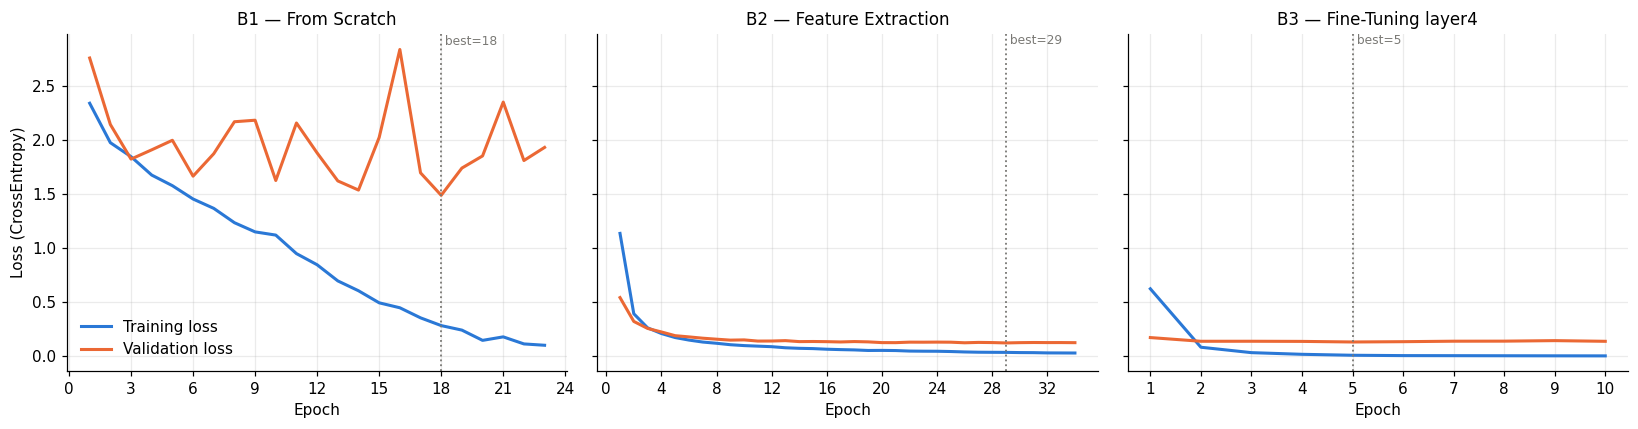

In [35]:
def plot_loss_panel(ax, exp_id, title):
    h, best = HISTORY[exp_id], RESULTS[exp_id]["best_epoch"]
    ax.plot(h["epoch"], h["train_loss"], color=C_TRAIN, lw=2, label="Training loss")
    ax.plot(h["epoch"], h["val_loss"], color=C_VAL, lw=2, label="Validation loss")
    ax.axvline(best, color=C_NEUTRAL, ls=":", lw=1.2)
    ax.text(best, ax.get_ylim()[1], f" best={best}", color=C_NEUTRAL, va="top", fontsize=8)
    ax.set_title(title); ax.set_xlabel("Epoch"); ax.xaxis.set_major_locator(MaxNLocator(integer=True))

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (eid, ttl) in zip(axes, [("B1", "B1 — From Scratch"), ("B2", "B2 — Feature Extraction"), ("B3", "B3 — Fine-Tuning layer4")]):
    plot_loss_panel(ax, eid, ttl)
axes[0].set_ylabel("Loss (CrossEntropy)")
axes[0].legend(loc="lower left", frameon=False)
plt.tight_layout()
plt.savefig(FIGS / "loss_curves_B1_B2_B3.png", dpi=200, bbox_inches="tight")
plt.show()

### C2 — Augmentation effect: accuracy curves and train–validation gap (B4)

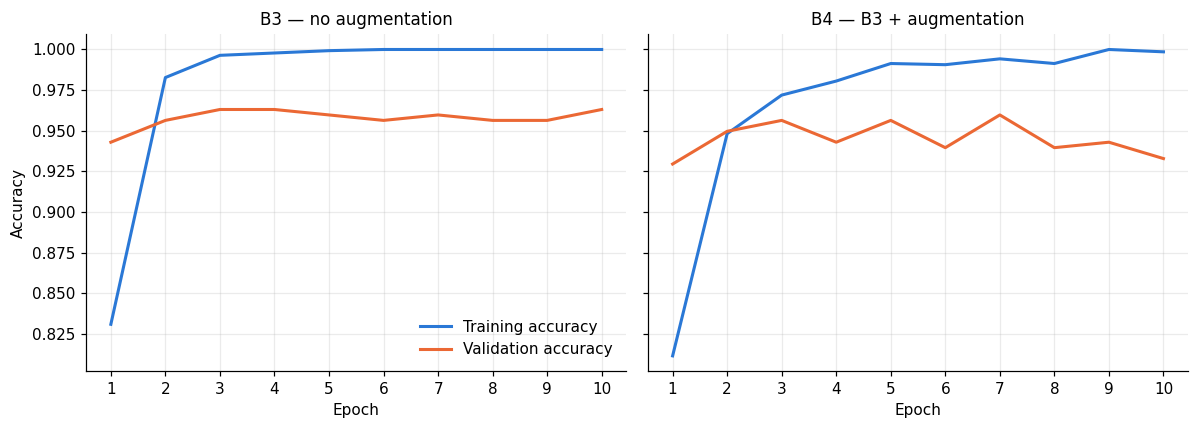

Note: training accuracy in the plot is measured during training (augmentation active in B4).
The 'generalization_gap' column uses training accuracy without augmentation (eval mode) for a like-for-like comparison.


In [36]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (eid, ttl) in zip(axes, [(base_id, f"{base_id} — no augmentation"), ("B4", f"B4 — {base_id} + augmentation")]):
    h = HISTORY[eid]
    ax.plot(h["epoch"], h["train_acc"], color=C_TRAIN, lw=2, label="Training accuracy")
    ax.plot(h["epoch"], h["val_acc"], color=C_VAL, lw=2, label="Validation accuracy")
    ax.set_title(ttl); ax.set_xlabel("Epoch"); ax.xaxis.set_major_locator(MaxNLocator(integer=True))
axes[0].set_ylabel("Accuracy"); axes[0].legend(loc="lower right", frameon=False)
plt.tight_layout()
plt.savefig(FIGS / "b4_accuracy_curves.png", dpi=200, bbox_inches="tight")
plt.show()
print("Note: training accuracy in the plot is measured during training (augmentation active in B4).")
print("The 'generalization_gap' column uses training accuracy without augmentation (eval mode) for a like-for-like comparison.")

### C3 — Failure Analysis
The best model is selected across all experiments by validation Macro F1. The test-set errors with the highest confidence are shown. The `failure_hypothesis` column in the CSV is left empty and is filled in after inspecting the images.

Best model (val Macro F1): B2 | test acc = 0.9463 | test macro-F1 = 0.9457
Misclassified: 16 of 298 test samples


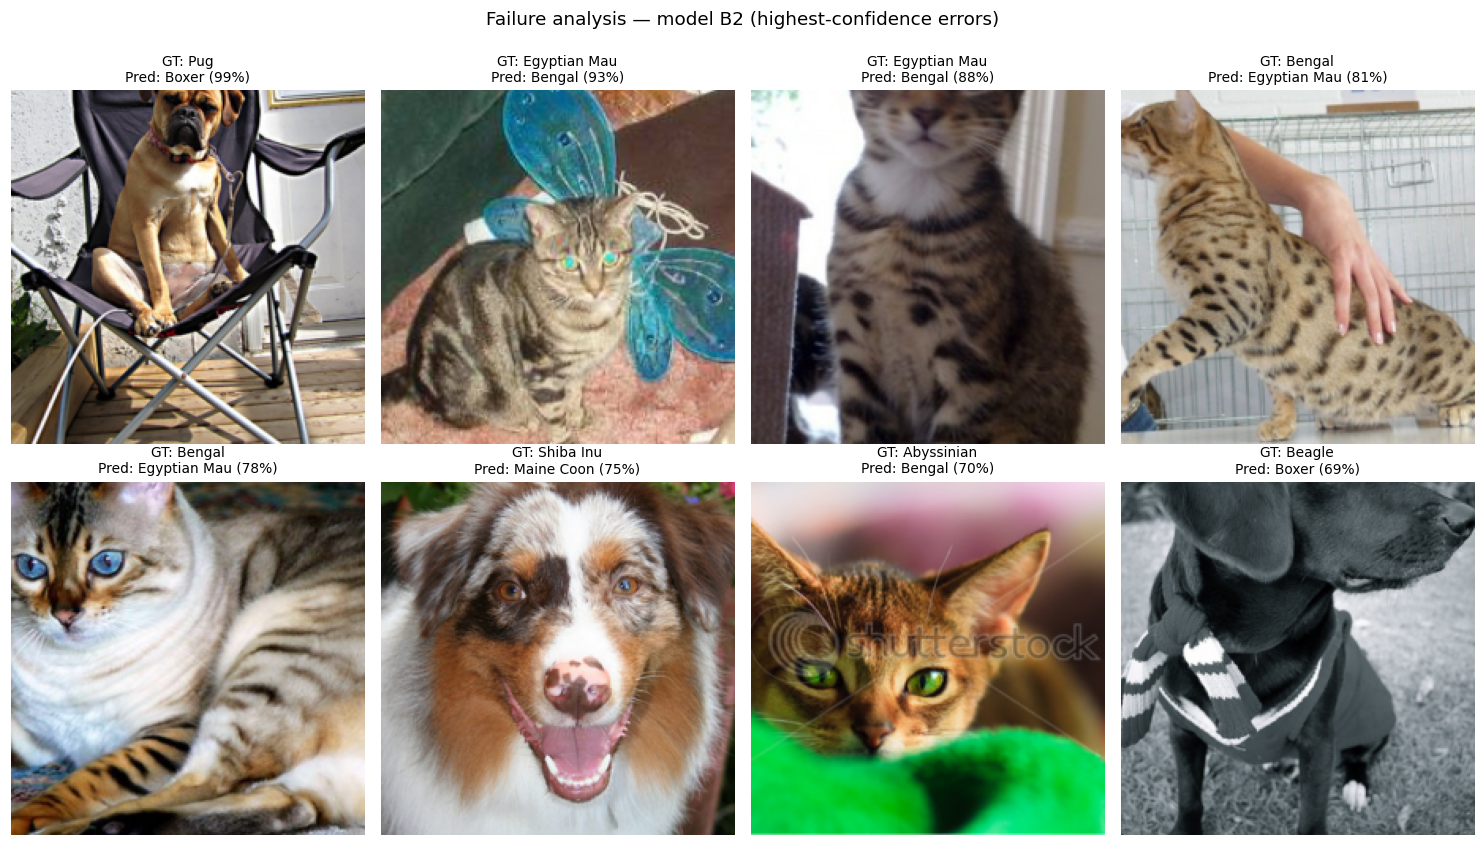

,file,ground_truth,prediction,confidence,prob_true_class,failure_hypothesis
0,pug_74.jpg,Pug,Boxer,0.9944,0.0017,
1,Egyptian_Mau_214.jpg,Egyptian Mau,Bengal,0.9332,0.0208,
2,Egyptian_Mau_84.jpg,Egyptian Mau,Bengal,0.8831,0.0664,
3,Bengal_2.jpg,Bengal,Egyptian Mau,0.8109,0.1891,
4,Bengal_188.jpg,Bengal,Egyptian Mau,0.7831,0.2028,
5,shiba_inu_156.jpg,Shiba Inu,Maine Coon,0.7482,0.0189,
6,Abyssinian_101.jpg,Abyssinian,Bengal,0.7032,0.1928,
7,beagle_198.jpg,Beagle,Boxer,0.6894,0.3047,


In [37]:
BEST_ID = pick_best(list(RESULTS))
print(f"Best model (val Macro F1): {BEST_ID} | test acc = {RESULTS[BEST_ID]['test_acc']:.4f} | test macro-F1 = {RESULTS[BEST_ID]['test_macro_f1']:.4f}")

FAIL_N = 8
res = PREDS[BEST_ID]
labels, preds, probs = res["labels"], res["preds"], res["probs"]
wrong = np.where(preds != labels)[0]
print(f"Misclassified: {len(wrong)} of {len(labels)} test samples")

if len(wrong) == 0:
    print("No misclassifications on the test set; run the failure analysis on another model or on the validation set.")
else:
    conf = probs[wrong, preds[wrong]]
    show = wrong[np.argsort(-conf)][:FAIL_N]
    if len(show) < 5:
        print(f"Only {len(show)} errors found; 5-8 samples are required (consider another model, e.g., B2).")

    center = transforms.CenterCrop(CFG["img_size"])
    ncols = 4; nrows = int(np.ceil(len(show) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.4 * ncols, 3.9 * nrows))
    axes = np.atleast_1d(axes).ravel()
    rows = []
    for ax, pos in zip(axes, show):
        g = int(idx_test[pos])
        gt, pr, c = SELECTED_CLASSES[labels[pos]], SELECTED_CLASSES[preds[pos]], probs[pos, preds[pos]]
        ax.imshow(center(IMAGES[g])); ax.axis("off")
        ax.set_title(f"GT: {gt}\nPred: {pr} ({c:.0%})", fontsize=9)
        rows.append({"file": NAMES[g], "ground_truth": gt, "prediction": pr, "confidence": round(float(c), 4),
                     "prob_true_class": round(float(probs[pos, labels[pos]]), 4), "failure_hypothesis": ""})
    for ax in axes[len(show):]:
        ax.axis("off")
    plt.suptitle(f"Failure analysis — model {BEST_ID} (highest-confidence errors)", y=1.0)
    plt.tight_layout()
    plt.savefig(FIGS / "failure_analysis.png", dpi=200, bbox_inches="tight")
    plt.show()
    pd.DataFrame(rows).to_csv(LOGS / "failure_cases.csv", index=False)
    display(pd.DataFrame(rows))

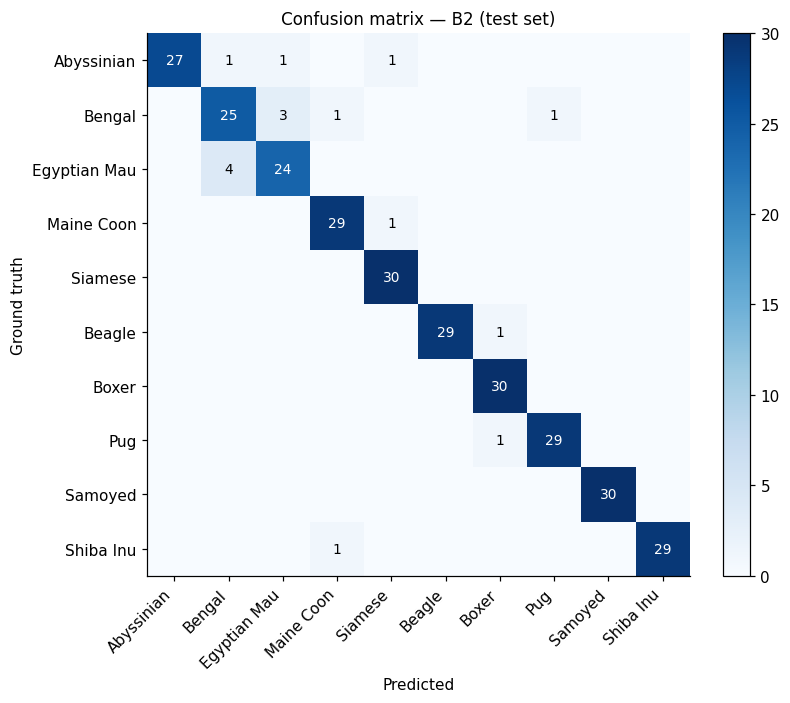

              precision    recall  f1-score   support

  Abyssinian       1.00      0.90      0.95        30
      Bengal       0.83      0.83      0.83        30
Egyptian Mau       0.86      0.86      0.86        28
  Maine Coon       0.94      0.97      0.95        30
     Siamese       0.94      1.00      0.97        30
      Beagle       1.00      0.97      0.98        30
       Boxer       0.94      1.00      0.97        30
         Pug       0.97      0.97      0.97        30
     Samoyed       1.00      1.00      1.00        30
   Shiba Inu       1.00      0.97      0.98        30

    accuracy                           0.95       298
   macro avg       0.95      0.95      0.95       298
weighted avg       0.95      0.95      0.95       298



In [38]:
# Confusion matrix and classification report of the best model
cm = confusion_matrix(labels, preds, labels=list(range(NUM_CLASSES)))
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(SELECTED_CLASSES, rotation=45, ha="right")
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(SELECTED_CLASSES)
ax.grid(False); ax.set_xlabel("Predicted"); ax.set_ylabel("Ground truth"); ax.set_title(f"Confusion matrix — {BEST_ID} (test set)")
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        if cm[i, j] > 0:
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=9,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.colorbar(im, fraction=0.046); plt.tight_layout()
plt.savefig(FIGS / "confusion_matrix_best.png", dpi=200, bbox_inches="tight"); plt.show()

report = classification_report(labels, preds, target_names=SELECTED_CLASSES, output_dict=True, zero_division=0)
pd.DataFrame(report).T.round(4).to_csv(LOGS / "classification_report_best.csv")
print(classification_report(labels, preds, target_names=SELECTED_CLASSES, zero_division=0))

### C5 (Optional) — Grad-CAM on `layer4`: before vs. after fine-tuning
Compares B2 (`layer4` frozen at ImageNet weights) with B3 (`layer4` fine-tuned) on the same test images. Set `RUN_GRADCAM = False` to skip.

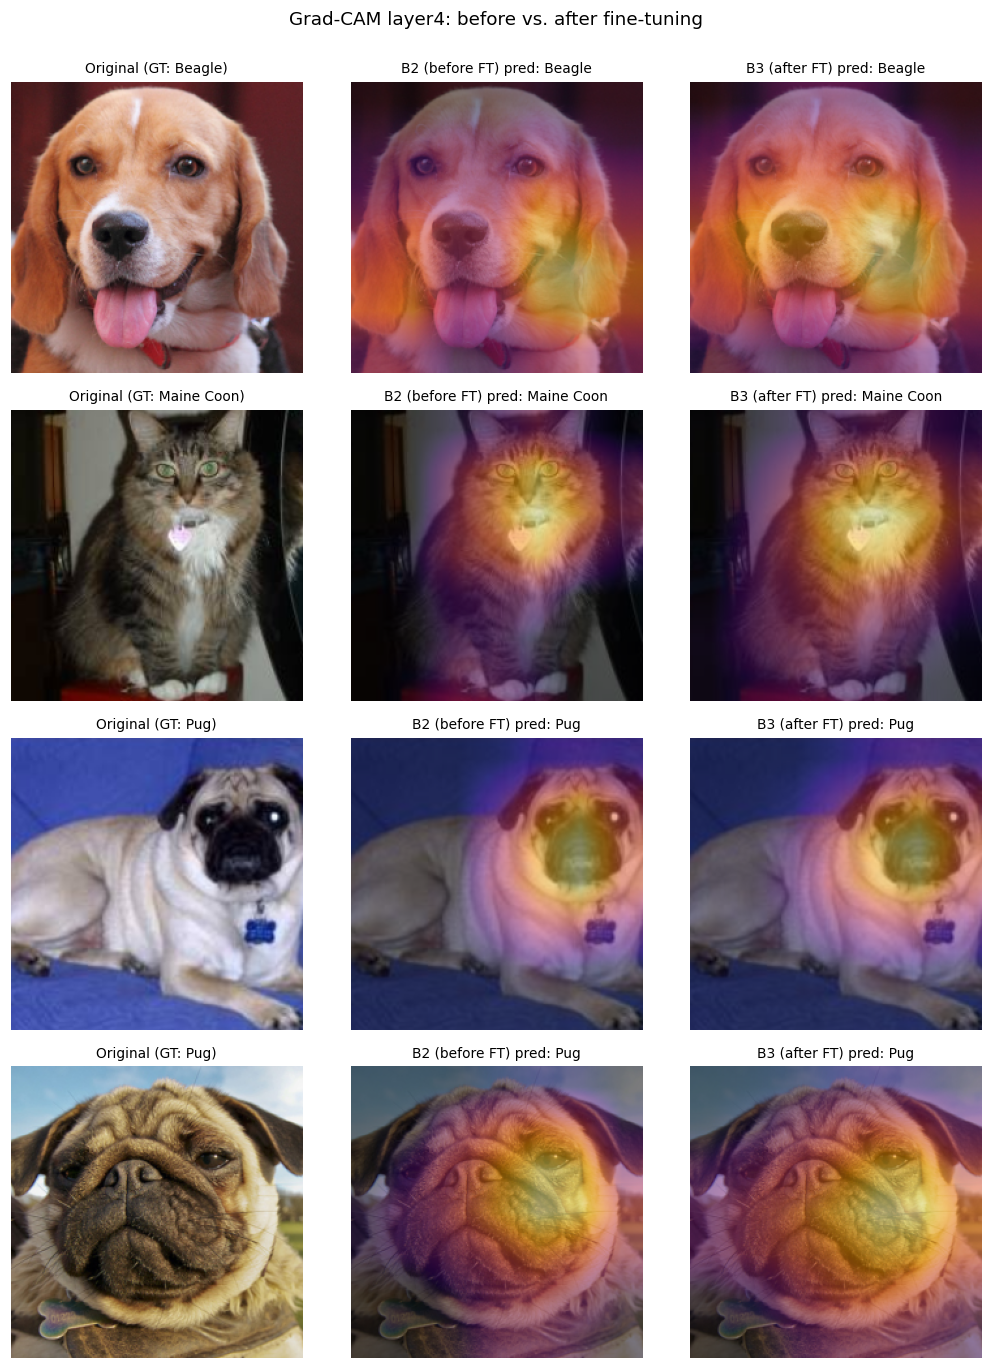

In [39]:
RUN_GRADCAM = True


# Grad-CAM on ResNet layer4: channel weights = mean gradient of the class score w.r.t. the activations
def gradcam_layer4(model, x):
    model.eval()
    store = {}
    h = model.layer4.register_forward_hook(lambda m, i, o: store.__setitem__("a", o))
    x = x.clone().requires_grad_(True)       # builds the gradient graph even though the backbone is frozen
    with torch.enable_grad():
        logits = model(x)
        cls = logits.argmax(1)
        score = logits.gather(1, cls[:, None]).sum()
        grads = torch.autograd.grad(score, store["a"])[0]
    h.remove()
    a = store["a"].detach()
    w = grads.mean(dim=(2, 3), keepdim=True)
    cam = F.relu((w * a).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=(CFG["img_size"],) * 2, mode="bilinear", align_corners=False)[:, 0]
    cam = cam / (cam.amax(dim=(1, 2), keepdim=True) + 1e-8)
    return cam.cpu().numpy(), cls.cpu().numpy()


def load_resnet_from_run(exp_id):
    b = build_model("resnet18", SPECS[exp_id]["strategy"], NUM_CLASSES, pretrained=False)
    b["model"].load_state_dict(torch.load(RESULTS[exp_id]["weights_file"], map_location="cpu"))
    return b["model"].to(DEVICE).eval()


if RUN_GRADCAM and "B2" in RESULTS and "B3" in RESULTS:
    m2, m3 = load_resnet_from_run("B2"), load_resnet_from_run("B3")
    rng = np.random.RandomState(CFG["seed"])
    pos = rng.choice(len(idx_test), size=4, replace=False)
    gidx = [int(idx_test[p]) for p in pos]
    x = torch.stack([eval_tf(IMAGES[g]) for g in gidx]).to(DEVICE)
    cam2, c2 = gradcam_layer4(m2, x)
    cam3, c3 = gradcam_layer4(m3, x)

    center = transforms.CenterCrop(CFG["img_size"])
    fig, axes = plt.subplots(len(gidx), 3, figsize=(9.5, 3.1 * len(gidx)))
    for r, g in enumerate(gidx):
        img = center(IMAGES[g])
        gt = SELECTED_CLASSES[LABELS[g]]
        axes[r, 0].imshow(img); axes[r, 0].set_title(f"Original (GT: {gt})", fontsize=9)
        axes[r, 1].imshow(img); axes[r, 1].imshow(cam2[r], cmap="inferno", alpha=0.5)
        axes[r, 1].set_title(f"B2 (before FT) pred: {SELECTED_CLASSES[c2[r]]}", fontsize=9)
        axes[r, 2].imshow(img); axes[r, 2].imshow(cam3[r], cmap="inferno", alpha=0.5)
        axes[r, 2].set_title(f"B3 (after FT) pred: {SELECTED_CLASSES[c3[r]]}", fontsize=9)
        for a in axes[r]: a.axis("off")
    plt.suptitle("Grad-CAM layer4: before vs. after fine-tuning", y=1.0)
    plt.tight_layout()
    plt.savefig(FIGS / "gradcam_B2_vs_B3.png", dpi=200, bbox_inches="tight"); plt.show()
    del m2, m3
else:
    print("Grad-CAM skipped.")

## 8. Export Artifacts
Writes run metadata and `requirements.txt`, then zips `logs/`, `figures/`, and `requirements.txt` into one archive. Model weights (`models/`) are excluded to keep the archive small.

In [40]:
pkgs = ["torch", "torchvision", "numpy", "pandas", "scikit-learn", "matplotlib", "Pillow", "tqdm"]
req = []
for p in pkgs:
    try:
        req.append(f"{p}=={md.version(p)}")
    except md.PackageNotFoundError:
        pass
(OUT / "requirements.txt").write_text("\n".join(req) + "\n")

meta = {
    "timestamp": datetime.now().isoformat(timespec="seconds"),
    "python": platform.python_version(), "torch": torch.__version__,
    "device": str(DEVICE), "gpu": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else None,
    "config": CFG, "selected_classes": SELECTED_CLASSES,
    "split_sizes": {"train": int(len(idx_train)), "val": int(len(idx_val)), "test": int(len(idx_test))},
    "best_model_by_val_macro_f1": BEST_ID,
}
with open(LOGS / "run_metadata.json", "w") as f:
    json.dump(meta, f, indent=2, default=str)

zip_path = Path("outputs_part_B.zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for sub in (LOGS, FIGS):
        for f in sorted(sub.rglob("*")):
            if f.is_file():
                z.write(f, f.relative_to(OUT))
    z.write(OUT / "requirements.txt", "requirements.txt")

print("Log files:", sorted(p.name for p in LOGS.iterdir()))
print("Figure files:", sorted(p.name for p in FIGS.iterdir()))
print("ZIP:", zip_path, f"({zip_path.stat().st_size / 1e6:.1f} MB)")

# Colab: download the ZIP directly
try:
    from google.colab import files
    files.download(str(zip_path))
except Exception:
    pass

Log files: ['b4_augmentation_comparison.csv', 'classification_report_best.csv', 'epoch_log.csv', 'failure_cases.csv', 'run_metadata.json', 'summary.csv', 'summary.json']
Figure files: ['b4_accuracy_curves.png', 'confusion_matrix_best.png', 'failure_analysis.png', 'gradcam_B2_vs_B3.png', 'loss_curves_B1_B2_B3.png']
ZIP: outputs_part_B.zip (7.6 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>